In [1]:
!pip install --upgrade binance-historical-data plotly -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 42.0 MB/s eta 0:00:00


In [2]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",  # spot, um, cm
        data_type="klines",  # aggTrades, klines, trades
        data_frequency="5m",
    )
    return data_dumper.get_list_all_trading_pairs()

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data



In [3]:
ticker = 'BTCUSDT'
data_frequency = '5m'
download_ticker(ticker, "2024-01-01", "2025-07-25", data_frequency)
data = process_csv_files(ticker, data_frequency)
data = data.drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
data.set_index('open_time', inplace=True)
data

---> Found overall tickers: 3205
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 5m
---> Start Date: 20240101
---> End Date: 20250725


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download:   0%|          | 0/18 [00:00<?, ?files/s]

daily files to download:   0%|          | 0/25 [00:00<?, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download:   0%|          | 0/25 [00:00<?, ?files/s]

Tried to dump data for 2 tickers:
---> For BTCUSDT new data saved for: 18 months 25 days
---> For CUSDT new data saved for: 0 months 8 days


,Open,High,Low,Close,volume
open_time,,,,,
2024-01-01 00:05:00,42397.22,42432.74,42385.26,42409.96,141.31102
2024-01-01 00:10:00,42409.97,42488.09,42409.96,42488.00,135.14249
2024-01-01 00:15:00,42488.00,42554.57,42458.58,42458.85,163.32541
2024-01-01 00:20:00,42458.85,42491.10,42445.84,42473.93,117.27112
2024-01-01 00:25:00,42473.93,42500.00,42412.02,42419.73,111.65236
...,...,...,...,...,...
2025-07-25 23:35:00,117350.07,117571.44,117350.07,117547.58,118.58042
2025-07-25 23:40:00,117547.58,117598.26,117532.41,117532.41,31.18831
2025-07-25 23:45:00,117532.41,117599.12,117522.40,117599.12,22.83026


In [4]:
# Calculate the candle length - difference between Close & Open
data['Close-Open'] = data['Close'] - data['Open']
data['Candle'] = np.where(data['Close-Open'] >= 0, 'green', 'red')
data['Mean_CO'] = abs(data['Close-Open']).rolling(window=5).mean()

# Calculate the boundary for signal
data['Trigger'] = data['Mean_CO']*2.5

data

,Open,High,Low,Close,volume,Close-Open,Candle,Mean_CO,Trigger
open_time,,,,,,,,,
2024-01-01 00:05:00,42397.22,42432.74,42385.26,42409.96,141.31102,12.74,green,NaN,NaN
2024-01-01 00:10:00,42409.97,42488.09,42409.96,42488.00,135.14249,78.03,green,NaN,NaN
2024-01-01 00:15:00,42488.00,42554.57,42458.58,42458.85,163.32541,-29.15,red,NaN,NaN
2024-01-01 00:20:00,42458.85,42491.10,42445.84,42473.93,117.27112,15.08,green,NaN,NaN
2024-01-01 00:25:00,42473.93,42500.00,42412.02,42419.73,111.65236,-54.20,red,37.840,94.600
...,...,...,...,...,...,...,...,...,...
2025-07-25 23:35:00,117350.07,117571.44,117350.07,117547.58,118.58042,197.51,green,82.608,206.520
2025-07-25 23:40:00,117547.58,117598.26,117532.41,117532.41,31.18831,-15.17,red,59.152,147.880
2025-07-25 23:45:00,117532.41,117599.12,117522.40,117599.12,22.83026,66.71,green,70.358,175.895


In [5]:
# The SL-TP for exit
data['Mean'] = ((data['Close']+data['Open'])*0.5).rolling(window=5).mean()

data['Stop_loss'] = data['Mean']*(1-0.05)
data['Take_profit'] = data['Mean']*(1+0.1)

data

,Open,High,Low,Close,volume,Close-Open,Candle,Mean_CO,Trigger,Mean,Stop_loss,Take_profit
open_time,,,,,,,,,,,,
2024-01-01 00:05:00,42397.22,42432.74,42385.26,42409.96,141.31102,12.74,green,NaN,NaN,NaN,NaN,NaN
2024-01-01 00:10:00,42409.97,42488.09,42409.96,42488.00,135.14249,78.03,green,NaN,NaN,NaN,NaN,NaN
2024-01-01 00:15:00,42488.00,42554.57,42458.58,42458.85,163.32541,-29.15,red,NaN,NaN,NaN,NaN,NaN
2024-01-01 00:20:00,42458.85,42491.10,42445.84,42473.93,117.27112,15.08,green,NaN,NaN,NaN,NaN,NaN
2024-01-01 00:25:00,42473.93,42500.00,42412.02,42419.73,111.65236,-54.20,red,37.840,94.600,42447.844,40325.45180,46692.6284
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-25 23:35:00,117350.07,117571.44,117350.07,117547.58,118.58042,197.51,green,82.608,206.520,117350.292,111482.77740,129085.3212
2025-07-25 23:40:00,117547.58,117598.26,117532.41,117532.41,31.18831,-15.17,red,59.152,147.880,117400.136,111530.12920,129140.1496
2025-07-25 23:45:00,117532.41,117599.12,117522.40,117599.12,22.83026,66.71,green,70.358,175.895,117442.957,111570.80915,129187.2527


In [6]:
data['Position'] = 0
data['Daily_change'] = 0
data['Real_returns'] = 0
data['Fee'] = 0

in_trade = False
entry_price = 0
position = 0
fee = 0.001 #Transaction cost

for i in range(1, len(data)):
    # Check for entry signal
    if not in_trade:
        if abs(data['Close-Open'][i-1]) >= data['Trigger'][i-1]:
            in_trade = True
            entry_price = data['Close'][i-1]
            if data['Close-Open'][i-1] > 0:
                position = -1 # Short
            else:
                position = 1 # Long
            data['Position'][i] = position
        else:
            data['Position'][i] = 0
            data['Daily_change'][i] = 0
            data['Fee'][i] = 0
    else:
        # Calculate Unrealised_pnL if in trade
        if position == 1: # Long
            unrealised_pnl = (data['Close'][i] - data['Open'][i]) / data['Open'][i]
        elif position == -1: # Short
            unrealised_pnl = (data['Open'][i] - data['Close'][i]) / data['Open'][i]

        data['Daily_change'][i] = unrealised_pnl

        # Check for exit signal (Stop Loss or Take Profit)
        current_price = data['Close'][i]
        if current_price <= data['Stop_loss'][i-1] or current_price >= data['Take_profit'][i-1]:
            # Calculate realised return:
            if position == 1: # Long
                realised_pnl = (current_price - entry_price) / entry_price
            elif position == -1: # Short
                realised_pnl = (entry_price - current_price) / entry_price

            in_trade = False
            entry_price = 0
            position = 0

            data['Fee'][i] = fee # Record transaction cost
            data['Real_returns'][i] = realised_pnl-data['Fee'][i]
        data['Position'][i] = position

data.head(50)

,Open,High,Low,Close,volume,Close-Open,Candle,Mean_CO,Trigger,Mean,Stop_loss,Take_profit,Position,Daily_change,Real_returns,Fee
open_time,,,,,,,,,,,,,,,,
2024-01-01 00:05:00,42397.22,42432.74,42385.26,42409.96,141.31102,12.74,green,NaN,NaN,NaN,NaN,NaN,0,0.000000e+00,0.0,0.0
2024-01-01 00:10:00,42409.97,42488.09,42409.96,42488.00,135.14249,78.03,green,NaN,NaN,NaN,NaN,NaN,0,0.000000e+00,0.0,0.0
2024-01-01 00:15:00,42488.00,42554.57,42458.58,42458.85,163.32541,-29.15,red,NaN,NaN,NaN,NaN,NaN,0,0.000000e+00,0.0,0.0
2024-01-01 00:20:00,42458.85,42491.10,42445.84,42473.93,117.27112,15.08,green,NaN,NaN,NaN,NaN,NaN,0,0.000000e+00,0.0,0.0
2024-01-01 00:25:00,42473.93,42500.00,42412.02,42419.73,111.65236,-54.20,red,37.840,94.600,42447.844,40325.45180,46692.6284,0,0.000000e+00,0.0,0.0
2024-01-01 00:30:00,42419.73,42419.73,42354.19,42362.93,77.85936,-56.80,red,46.652,116.630,42445.392,40323.12240,46689.9312,0,0.000000e+00,0.0,0.0
2024-01-01 00:35:00,42362.93,42447.82,42355.36,42447.82,149.18862,84.89,green,48.024,120.060,42436.670,40314.83650,46680.3370,0,0.000000e+00,0.0,0.0
2024-01-01 00:40:00,42447.82,42447.82,42396.50,42441.32,92.85846,-6.50,red,43.494,108.735,42430.899,40309.35405,46673.9889,0,0.000000e+00,0.0,0.0
2024-01-01 00:45:00,42441.32,42465.52,42422.45,42422.46,59.74817,-18.86,red,44.250,110.625,42423.999,40302.79905,46666.3989,0,0.000000e+00,0.0,0.0


In [7]:
# # Position to take
# conditions = [
#     (abs(data['Close-Open']) >= data['Signal'].shift(1)) & (data['Candle'].shift(1)=='green'),
#     (abs(data['Close-Open']) >= data['Signal'].shift(1)) & (data['Candle'].shift(1)=='red'),
#     (abs(data['Close-Open']) < data['Signal'].shift(1))
# ]
# choices = [-1, 1, 0]
# data['Position'] = np.select(conditions, choices, default=0)

# data['PnL'] = 0
# data['Unrealised'] = 0
# for i in range(len(data)-1):
#   if data['Position'][i] != data['Position'][i+1]:
#     data['Unrealised'][i+1] = 0.0005
#   data['PnL'][i+1] = (data['Close'][i+1]/data['Open'][i+1]-1)*data['Position'][i]

# data['Real_returns'] = data['PnL']-data['Unrealised']

# data.head(50)

In [8]:
def get_periods_per_year(freq: str) -> int:
    if freq.endswith('m'):  # phút
        minutes = int(freq[:-1])
        return int(365 * 24 * 60 / minutes)
    elif freq.endswith('h'):  # giờ
        hours = int(freq[:-1])
        return int(365 * 24 / hours)
    elif freq.endswith('d'):  # ngày
        return 365
    elif freq.endswith('w'):  # tuần
        return 52
    else:
        raise ValueError(f"Không hỗ trợ định dạng data_frequency: {freq}")

def calculate_sharpe_ratio(returns_series: pd.Series, data_frequency: str, annualized_risk_free_rate: float = 0.03) -> float:
    """
    Tính toán Sharpe Ratio hàng năm từ một chuỗi lợi nhuận theo kỳ.

    Args:
        returns_series (pd.Series): Chuỗi lợi nhuận của chiến lược theo từng kỳ.
        data_frequency (str): Tần suất của dữ liệu ('15m', '1H', '1D').
        annualized_risk_free_rate (float): Lãi suất phi rủi ro hàng năm.

    Returns:
        float: Giá trị Sharpe Ratio đã được quy đổi ra năm.
    """
    # Xử lý trường hợp không có giao dịch hoặc không có biến động
    if returns_series.std() == 0 or pd.isna(returns_series.std()):
        return 0.0

    # 1. Lấy số kỳ trong một năm
    periods_per_year = get_periods_per_year(data_frequency)

    # 2. Quy đổi lãi suất phi rủi ro ra theo từng kỳ
    rf_per_period = annualized_risk_free_rate / periods_per_year

    # 3. Tính toán Sharpe Ratio
    # Lợi nhuận trung bình mỗi kỳ trừ đi lãi suất phi rủi ro mỗi kỳ
    excess_return_mean = returns_series.mean() - rf_per_period

    # Sharpe Ratio hàng ngày = Lợi nhuận vượt trội trung bình / Độ lệch chuẩn lợi nhuận
    sharpe_ratio = excess_return_mean / returns_series.std()

    # 4. Quy đổi ra Sharpe Ratio hàng năm
    annualized_sharpe = sharpe_ratio * np.sqrt(periods_per_year)

    return annualized_sharpe

def calculate_max_drawdown(returns_series: pd.Series) -> float:
    """Tính toán Maximum Drawdown từ một chuỗi lợi nhuận."""
    equity_curve = (1 + returns_series).cumprod()
    peak = equity_curve.expanding(min_periods=1).max()
    drawdown = (equity_curve - peak) / peak
    return drawdown.min()


period_per_year = get_periods_per_year(data_frequency)
real_return = data['Real_returns']

sharpe_ratio = calculate_sharpe_ratio(real_return, data_frequency)
max_drawdown = calculate_max_drawdown(real_return)

has_non_zero = (data['Position'] != 0).sum()
print("Column has non-zero:", has_non_zero)

# Calculate cumulative returns
Cumulative_Return = (1 + data['Real_returns']).cumprod()


# # Calculate Drawdown
# data['Peak'] = data['Cumulative_Return'].cummax()
# data['Drawdown'] = data['Peak'] - data['Cumulative_Return']

# # Calculate Max Drawdown
# max_drawdown = data['Drawdown'].max()

# # Calculate Average Drawdown (excluding zero drawdown periods)
# average_drawdown = data[data['Drawdown'] > 0]['Drawdown'].mean()

print(f"Sharpe Ratio: {sharpe_ratio}")
print(f"Max Drawdown: {max_drawdown}")
print(f"Return: {Cumulative_Return}")

# pnls = data['PnL']
# for pnl in pnls:
#   if pnl != 0:
#     print (pnl)

Column has non-zero: 164623
Sharpe Ratio: 0.4416079533339056
Max Drawdown: -0.2005584295615006
Return: open_time
2024-01-01 00:05:00    1.00000
2024-01-01 00:10:00    1.00000
2024-01-01 00:15:00    1.00000
2024-01-01 00:20:00    1.00000
2024-01-01 00:25:00    1.00000
                        ...   
2025-07-25 23:35:00    1.25685
2025-07-25 23:40:00    1.25685
2025-07-25 23:45:00    1.25685
2025-07-25 23:50:00    1.25685
2025-07-25 23:55:00    1.25685
Name: Real_returns, Length: 164693, dtype: float64


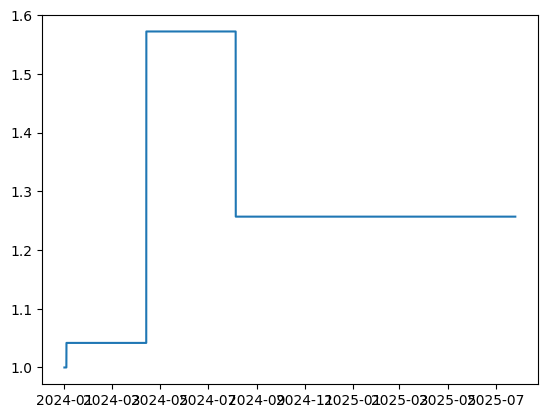

In [9]:
dates = data.index
# Plot profit
# plt.plot(unrealised_dates, np.cumprod(1+np.array(unrealised))-1)
# plt.plot(dates, np.cumprod(1+np.array(pnls))-1)
plt.plot(dates, Cumulative_Return)
# plt.plot(unrlzd_dates,np.cumprod(1+np.array(unrlzd)))
#plt.plot(unrlzd_dates, np.cumsum(unrlzd))